
Loading: Little ..\EMG Recordings\little_finger_30mins_combined.csv
Rows: 971827
Sessions: <StringArray>
['5min', '10min', '15min']
Length: 3, dtype: str
5min duration: 304.75 seconds windows: 304
10min duration: 607.72 seconds windows: 607
15min duration: 908.58 seconds windows: 908

Loading: Middle ..\EMG Recordings\middle_finger_30mins_combined.csv
Rows: 1086342
Sessions: <StringArray>
['5min', '10min', '15min']
Length: 3, dtype: str
5min duration: 305.74 seconds windows: 305
10min duration: 618.18 seconds windows: 618
15min duration: 1021.97 seconds windows: 1021

Loading: Ring ..\EMG Recordings\ring_finger_30mins_combined.csv
Rows: 994165
Sessions: <StringArray>
['5min', '10min', '15min']
Length: 3, dtype: str
5min duration: 329.09 seconds windows: 329
10min duration: 609.33 seconds windows: 609
15min duration: 930.55 seconds windows: 930

Loading: Index ..\EMG Recordings\index_finger_30mins_combined.csv
Rows: 1015193
Sessions: <StringArray>
['5min', '10min', '15min']
Length: 3, 

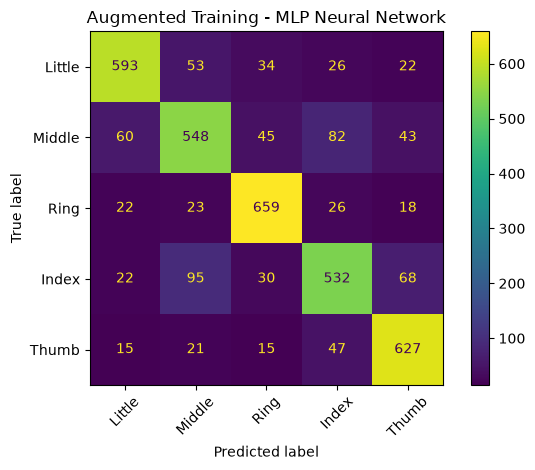

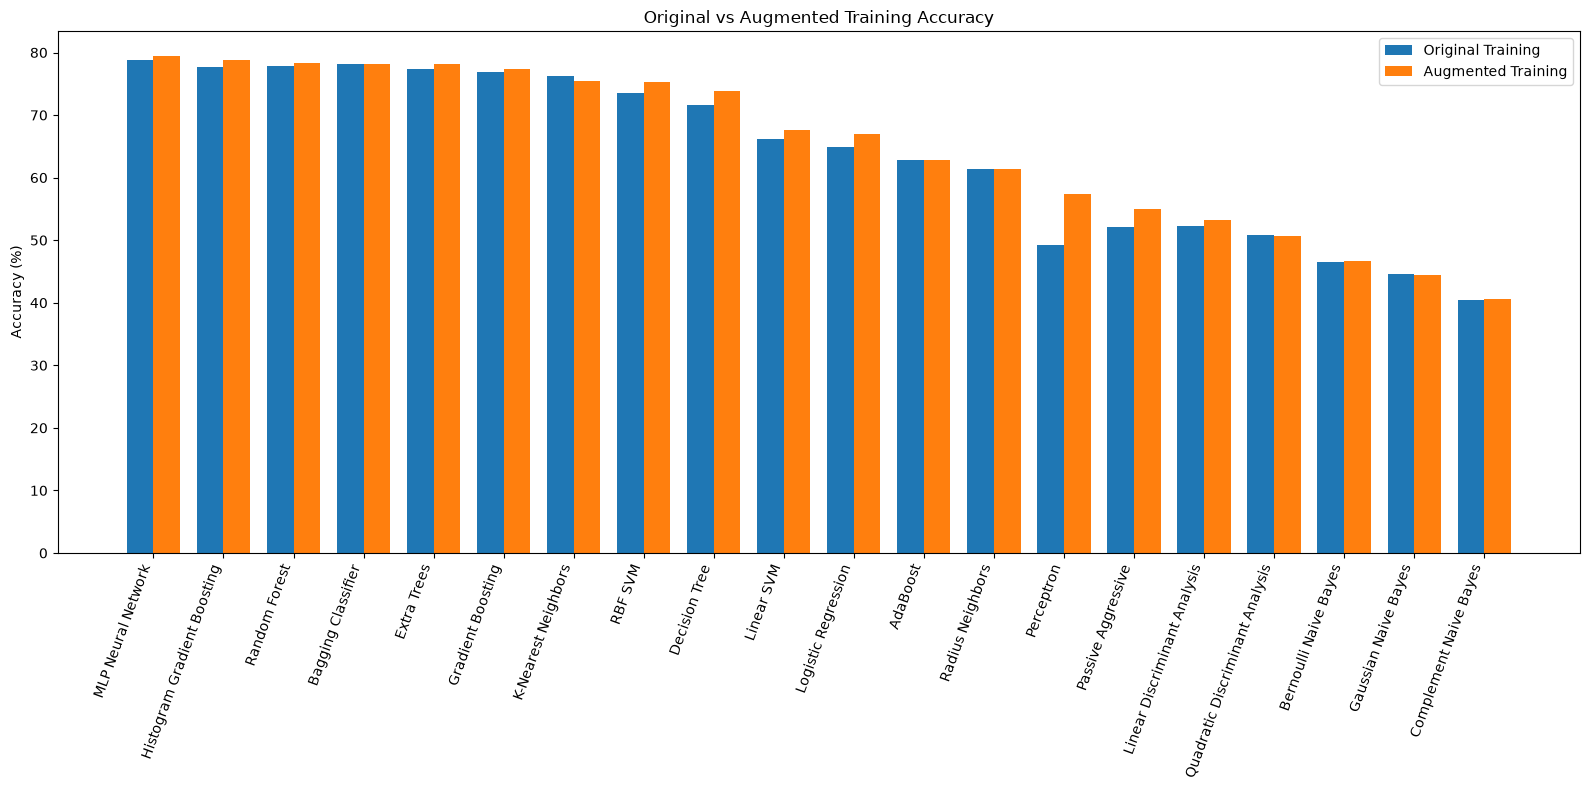

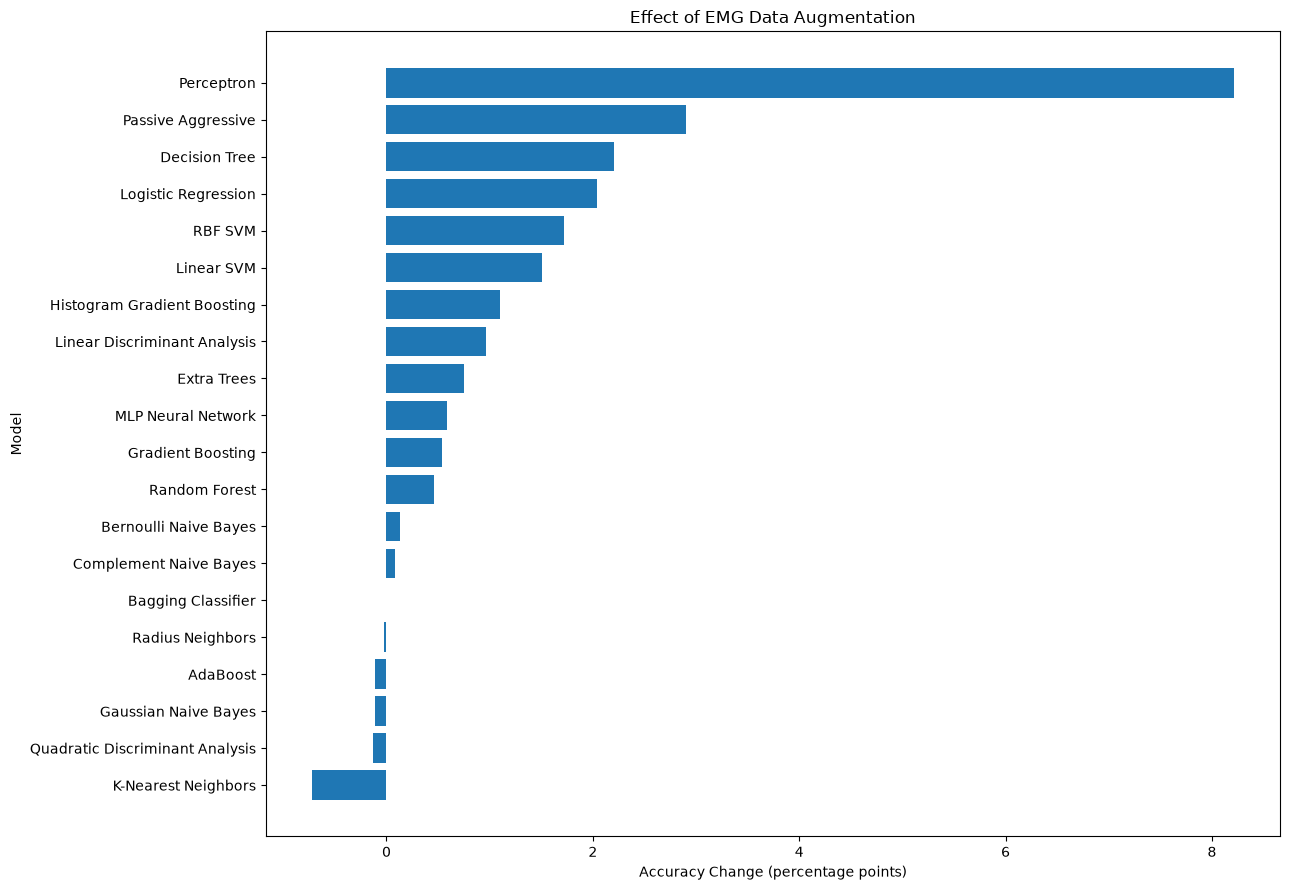


Random untouched test window
Actual finger: Index
Session: 10min
Logistic Regression                Index
K-Nearest Neighbors                Index
RBF SVM                            Index
Linear SVM                         Index
Decision Tree                      Index
Random Forest                      Index
Extra Trees                        Index
Histogram Gradient Boosting        Index
Gaussian Naive Bayes               Index
MLP Neural Network                 Index
Linear Discriminant Analysis       Thumb
Quadratic Discriminant Analysis    Index
Perceptron                         Middle
Passive Aggressive                 Index
Bernoulli Naive Bayes              Ring
Complement Naive Bayes             Thumb
AdaBoost                           Index
Bagging Classifier                 Index
Gradient Boosting                  Index
Radius Neighbors                   Index

Augmented Random Forest Feature Importance

                        Feature  Importance
                      EMG

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import (
    LogisticRegression,
    Perceptron,
    PassiveAggressiveClassifier
)

from sklearn.neighbors import (
    KNeighborsClassifier,
    RadiusNeighborsClassifier
)

from sklearn.svm import (
    SVC,
    LinearSVC
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier
)

from sklearn.naive_bayes import (
    GaussianNB,
    BernoulliNB,
    ComplementNB
)

from sklearn.neural_network import MLPClassifier

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
WINDOW_SECONDS = 1.0
AUGMENTATIONS_PER_WINDOW = 3

AMPLITUDE_MIN = 0.92
AMPLITUDE_MAX = 1.08
MAX_NOISE_FRACTION = 0.02
MAX_BASELINE_SHIFT_FRACTION = 0.02
DEAD_CHANNEL_STD_THRESHOLD = 1.0

rng = np.random.default_rng(
    RANDOM_STATE
)

data_folder = Path(
    "../EMG Recordings"
)


def resolve_file(names):

    for name in names:

        path = data_folder / name

        if path.exists():
            return path

    raise FileNotFoundError(
        "Could not find any of these files:\n"
        +
        "\n".join(names)
    )


files = {

    "Little": resolve_file([
        "little_finger_30mins_combined.csv"
    ]),

    "Middle": resolve_file([
        "middle_finger_30mins_combined.csv",
        "middle_finger_30mins_combined(2).csv"
    ]),

    "Ring": resolve_file([
        "ring_finger_30mins_combined.csv",
        "ring_finger_30mins_combined(2).csv"
    ]),

    "Index": resolve_file([
        "index_finger_30mins_combined.csv",
        "index_finger_30mins_combined(2).csv"
    ]),

    "Thumb": resolve_file([
        "thumb_finger_30mins_combined.csv",
        "thumb_finger_30mins_combined(2).csv"
    ])
}


all_windows = []
finger_labels = []
session_labels = []

observed_min = np.inf
observed_max = -np.inf


for finger, file_path in files.items():

    print(
        "\nLoading:",
        finger,
        file_path
    )

    data = pd.read_csv(
        file_path
    )

    required_columns = [
        "time_s",
        "emg1",
        "emg2"
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in data.columns
    ]

    if missing_columns:

        raise ValueError(
            f"{file_path} is missing "
            f"{missing_columns}"
        )

    for column in required_columns:

        data[column] = pd.to_numeric(
            data[column],
            errors="coerce"
        )

    data = data.dropna(
        subset=required_columns
    ).reset_index(
        drop=True
    )

    if "session" not in data.columns:

        data["session"] = "combined"

    data["session"] = (
        data["session"]
        .astype(str)
    )

    if "session_time_s" not in data.columns:

        data["session_time_s"] = (
            data.groupby(
                "session"
            )["time_s"]
            .transform(
                lambda values:
                    values
                    -
                    values.iloc[0]
            )
        )

    data["session_time_s"] = pd.to_numeric(
        data["session_time_s"],
        errors="coerce"
    )

    data = data.dropna(
        subset=[
            "session_time_s"
        ]
    ).reset_index(
        drop=True
    )

    current_min = data[
        [
            "emg1",
            "emg2"
        ]
    ].min().min()

    current_max = data[
        [
            "emg1",
            "emg2"
        ]
    ].max().max()

    observed_min = min(
        observed_min,
        current_min
    )

    observed_max = max(
        observed_max,
        current_max
    )

    print(
        "Rows:",
        len(data)
    )

    print(
        "Sessions:",
        data["session"].unique()
    )

    for session_name in (
        data["session"]
        .drop_duplicates()
        .tolist()
    ):

        session_data = data[
            data["session"]
            ==
            session_name
        ].copy()

        session_data = (
            session_data
            .sort_values(
                "session_time_s"
            )
            .reset_index(
                drop=True
            )
        )

        duration = session_data[
            "session_time_s"
        ].iloc[-1]

        number_of_complete_windows = int(
            np.floor(
                duration
                /
                WINDOW_SECONDS
            )
        )

        if number_of_complete_windows <= 0:
            continue

        session_data[
            "window_id"
        ] = np.floor(
            session_data[
                "session_time_s"
            ]
            /
            WINDOW_SECONDS
        ).astype(int)

        session_data = session_data[
            session_data[
                "window_id"
            ]
            <
            number_of_complete_windows
        ]

        number_created = 0

        for window_id, window_data in (
            session_data.groupby(
                "window_id",
                sort=True
            )
        ):

            if len(window_data) < 2:
                continue

            signal = window_data[
                [
                    "emg1",
                    "emg2"
                ]
            ].to_numpy(
                dtype=np.float32
            )

            all_windows.append(
                signal
            )

            finger_labels.append(
                finger
            )

            session_labels.append(
                session_name
            )

            number_created += 1

        print(
            session_name,
            "duration:",
            round(
                duration,
                2
            ),
            "seconds",
            "windows:",
            number_created
        )


finger_labels = np.array(
    finger_labels
)

session_labels = np.array(
    session_labels
)


if observed_min >= 0:

    ADC_MIN = 0.0

else:

    ADC_MIN = float(
        observed_min
    )


if observed_max <= 1023:

    ADC_MAX = 1023.0

elif observed_max <= 4095:

    ADC_MAX = 4095.0

else:

    ADC_MAX = float(
        observed_max
    )


print(
    "\nADC minimum:",
    ADC_MIN
)

print(
    "ADC maximum:",
    ADC_MAX
)

print(
    "\nTotal real windows:",
    len(
        all_windows
    )
)


print(
    "\nFinger distribution:"
)

print(
    pd.Series(
        finger_labels
    ).value_counts()
)


print(
    "\nSession distribution:"
)

print(
    pd.Series(
        session_labels
    ).value_counts()
)


stratification_labels = np.array(
    [
        f"{finger}_{session}"
        for finger, session
        in zip(
            finger_labels,
            session_labels
        )
    ]
)


all_indices = np.arange(
    len(
        all_windows
    )
)


train_indices, test_indices = (
    train_test_split(
        all_indices,
        train_size=0.60,
        test_size=0.40,
        random_state=RANDOM_STATE,
        shuffle=True,
        stratify=stratification_labels
    )
)


train_labels = finger_labels[
    train_indices
]

test_labels = finger_labels[
    test_indices
]

train_sessions = session_labels[
    train_indices
]

test_sessions = session_labels[
    test_indices
]


print(
    "\nReal training windows:",
    len(
        train_indices
    )
)

print(
    "Untouched testing windows:",
    len(
        test_indices
    )
)


print(
    "\nTraining finger distribution:"
)

print(
    pd.Series(
        train_labels
    ).value_counts()
)


print(
    "\nTesting finger distribution:"
)

print(
    pd.Series(
        test_labels
    ).value_counts()
)


print(
    "\nTraining session distribution:"
)

print(
    pd.Series(
        train_sessions
    ).value_counts()
)


print(
    "\nTesting session distribution:"
)

print(
    pd.Series(
        test_sessions
    ).value_counts()
)


statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Normalized_Waveform_Length"
]


feature_names = []


for statistic in statistic_names:

    feature_names.append(
        f"EMG1_{statistic}"
    )


for statistic in statistic_names:

    feature_names.append(
        f"EMG2_{statistic}"
    )


def calculate_statistics(values):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    mean_value = np.mean(
        values
    )

    median_value = np.median(
        values
    )

    minimum_value = np.min(
        values
    )

    maximum_value = np.max(
        values
    )

    standard_deviation = np.std(
        values
    )

    variance_value = np.var(
        values
    )

    value_range = (
        maximum_value
        -
        minimum_value
    )

    rms_value = np.sqrt(
        np.mean(
            values ** 2
        )
    )

    mean_absolute_value = np.mean(
        np.abs(
            values
        )
    )

    if len(values) > 1:

        normalized_waveform_length = (
            np.sum(
                np.abs(
                    np.diff(
                        values
                    )
                )
            )
            /
            (
                len(values)
                -
                1
            )
        )

    else:

        normalized_waveform_length = 0.0

    return np.array(
        [
            mean_value,
            median_value,
            minimum_value,
            maximum_value,
            standard_deviation,
            variance_value,
            value_range,
            rms_value,
            mean_absolute_value,
            normalized_waveform_length
        ],
        dtype=np.float64
    )


def extract_features(signal):

    emg1_features = (
        calculate_statistics(
            signal[:, 0]
        )
    )

    emg2_features = (
        calculate_statistics(
            signal[:, 1]
        )
    )

    return np.concatenate(
        [
            emg1_features,
            emg2_features
        ]
    )


def augment_channel(
    channel,
    random_generator
):

    channel = np.asarray(
        channel,
        dtype=np.float64
    )

    channel_standard_deviation = (
        np.std(
            channel
        )
    )

    if (
        channel_standard_deviation
        <
        DEAD_CHANNEL_STD_THRESHOLD
    ):

        return channel.copy()

    mean_value = np.mean(
        channel
    )

    amplitude_scale = (
        random_generator.uniform(
            AMPLITUDE_MIN,
            AMPLITUDE_MAX
        )
    )

    noise_fraction = (
        random_generator.uniform(
            0.005,
            MAX_NOISE_FRACTION
        )
    )

    baseline_fraction = (
        random_generator.uniform(
            -MAX_BASELINE_SHIFT_FRACTION,
            MAX_BASELINE_SHIFT_FRACTION
        )
    )

    noise = (
        random_generator.normal(
            0.0,
            channel_standard_deviation
            *
            noise_fraction,
            size=len(
                channel
            )
        )
    )

    baseline_shift = (
        channel_standard_deviation
        *
        baseline_fraction
    )

    augmented = (
        mean_value
        +
        (
            channel
            -
            mean_value
        )
        *
        amplitude_scale
        +
        noise
        +
        baseline_shift
    )

    zero_mask = (
        channel
        <=
        ADC_MIN
    )

    saturation_mask = (
        channel
        >=
        ADC_MAX
    )

    augmented = np.clip(
        augmented,
        ADC_MIN,
        ADC_MAX
    )

    augmented[
        zero_mask
    ] = channel[
        zero_mask
    ]

    augmented[
        saturation_mask
    ] = channel[
        saturation_mask
    ]

    return augmented


def augment_window(
    signal,
    random_generator
):

    augmented = np.array(
        signal,
        dtype=np.float64,
        copy=True
    )

    augmented[
        :,
        0
    ] = augment_channel(
        augmented[
            :,
            0
        ],
        random_generator
    )

    augmented[
        :,
        1
    ] = augment_channel(
        augmented[
            :,
            1
        ],
        random_generator
    )

    return augmented


print(
    "\nExtracting original training features..."
)


original_train_features = np.vstack(
    [
        extract_features(
            all_windows[index]
        )
        for index in train_indices
    ]
)


print(
    "Extracting untouched testing features..."
)


test_features = np.vstack(
    [
        extract_features(
            all_windows[index]
        )
        for index in test_indices
    ]
)


print(
    "Original training feature shape:",
    original_train_features.shape
)


print(
    "Test feature shape:",
    test_features.shape
)


augmented_feature_blocks = [
    original_train_features
]

augmented_label_blocks = [
    train_labels.copy()
]

augmented_session_blocks = [
    train_sessions.copy()
]

source_blocks = [
    np.array(
        [
            "Original"
        ]
        *
        len(
            train_indices
        )
    )
]


for augmentation_number in range(
    1,
    AUGMENTATIONS_PER_WINDOW + 1
):

    print(
        "\nCreating augmentation",
        augmentation_number,
        "of",
        AUGMENTATIONS_PER_WINDOW
    )

    current_features = []

    for position, index in enumerate(
        train_indices
    ):

        augmented_signal = (
            augment_window(
                all_windows[index],
                rng
            )
        )

        augmented_features = (
            extract_features(
                augmented_signal
            )
        )

        current_features.append(
            augmented_features
        )

    current_features = np.vstack(
        current_features
    )

    augmented_feature_blocks.append(
        current_features
    )

    augmented_label_blocks.append(
        train_labels.copy()
    )

    augmented_session_blocks.append(
        train_sessions.copy()
    )

    source_blocks.append(
        np.array(
            [
                f"Augmentation_{augmentation_number}"
            ]
            *
            len(
                train_indices
            )
        )
    )


augmented_train_features = np.vstack(
    augmented_feature_blocks
)


augmented_train_labels = np.concatenate(
    augmented_label_blocks
)


augmented_train_sessions = np.concatenate(
    augmented_session_blocks
)


augmentation_sources = np.concatenate(
    source_blocks
)


print(
    "\nOriginal training samples:",
    len(
        original_train_features
    )
)


print(
    "Augmented training samples:",
    len(
        augmented_train_features
    )
)


print(
    "Untouched test samples:",
    len(
        test_features
    )
)


print(
    "\nAugmented training distribution:"
)


print(
    pd.Series(
        augmented_train_labels
    ).value_counts()
)


augmented_feature_dataframe = pd.DataFrame(
    augmented_train_features,
    columns=feature_names
)


augmented_feature_dataframe[
    "finger"
] = augmented_train_labels


augmented_feature_dataframe[
    "session"
] = augmented_train_sessions


augmented_feature_dataframe[
    "source"
] = augmentation_sources


augmented_feature_dataframe.to_csv(
    "augmented_training_features.csv",
    index=False
)


print(
    "\nSaved:",
    "augmented_training_features.csv"
)


models = {

    "Logistic Regression":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=3000,
                    random_state=RANDOM_STATE
                )
            )
        ]),

    "K-Nearest Neighbors":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                KNeighborsClassifier(
                    n_neighbors=7,
                    weights="distance",
                    n_jobs=-1
                )
            )
        ]),

    "RBF SVM":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                SVC(
                    kernel="rbf",
                    C=3.0,
                    gamma="scale"
                )
            )
        ]),

    "Linear SVM":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearSVC(
                    C=1.0,
                    max_iter=5000,
                    random_state=RANDOM_STATE
                )
            )
        ]),

    "Decision Tree":

        DecisionTreeClassifier(
            min_samples_leaf=2,
            random_state=RANDOM_STATE
        ),

    "Random Forest":

        RandomForestClassifier(
            n_estimators=250,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

    "Extra Trees":

        ExtraTreesClassifier(
            n_estimators=250,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

    "Histogram Gradient Boosting":

        HistGradientBoostingClassifier(
            learning_rate=0.08,
            max_iter=200,
            max_leaf_nodes=31,
            random_state=RANDOM_STATE
        ),

    "Gaussian Naive Bayes":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                GaussianNB()
            )
        ]),

    "MLP Neural Network":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                MLPClassifier(
                    hidden_layer_sizes=(
                        128,
                        64
                    ),
                    activation="relu",
                    learning_rate_init=0.001,
                    max_iter=300,
                    early_stopping=True,
                    validation_fraction=0.10,
                    n_iter_no_change=15,
                    random_state=RANDOM_STATE
                )
            )
        ]),

    "Linear Discriminant Analysis":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearDiscriminantAnalysis(
                    solver="lsqr",
                    shrinkage="auto"
                )
            )
        ]),

    "Quadratic Discriminant Analysis":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                QuadraticDiscriminantAnalysis(
                    reg_param=0.2
                )
            )
        ]),

    "Perceptron":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Perceptron(
                    max_iter=2000,
                    tol=1e-3,
                    random_state=RANDOM_STATE
                )
            )
        ]),

    "Passive Aggressive":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                PassiveAggressiveClassifier(
                    C=1.0,
                    max_iter=2000,
                    tol=1e-3,
                    random_state=RANDOM_STATE
                )
            )
        ]),

    "Bernoulli Naive Bayes":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                BernoulliNB(
                    alpha=1.0
                )
            )
        ]),

    "Complement Naive Bayes":

        Pipeline([
            (
                "scaler",
                MinMaxScaler(
                    clip=True
                )
            ),
            (
                "model",
                ComplementNB(
                    alpha=1.0
                )
            )
        ]),

    "AdaBoost":

        AdaBoostClassifier(
            n_estimators=150,
            learning_rate=0.5,
            random_state=RANDOM_STATE
        ),

    "Bagging Classifier":

        BaggingClassifier(
            n_estimators=100,
            max_samples=0.8,
            max_features=1.0,
            n_jobs=-1,
            random_state=RANDOM_STATE
        ),

    "Gradient Boosting":

        GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.08,
            max_depth=3,
            random_state=RANDOM_STATE
        ),

    "Radius Neighbors":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                RadiusNeighborsClassifier(
                    radius=5.0,
                    weights="distance",
                    outlier_label="most_frequent",
                    n_jobs=-1
                )
            )
        ])
}


def calculate_metrics(
    actual,
    predicted
):

    return {

        "Accuracy":
            accuracy_score(
                actual,
                predicted
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                actual,
                predicted
            ),

        "Macro Precision":
            precision_score(
                actual,
                predicted,
                average="macro",
                zero_division=0
            ),

        "Macro Recall":
            recall_score(
                actual,
                predicted,
                average="macro",
                zero_division=0
            ),

        "Macro F1":
            f1_score(
                actual,
                predicted,
                average="macro",
                zero_division=0
            ),

        "Weighted F1":
            f1_score(
                actual,
                predicted,
                average="weighted",
                zero_division=0
            )
    }


comparison_results = []

original_models = {}

augmented_models = {}

original_predictions = {}

augmented_predictions = {}


print(
    "\nTraining 20 models on original and augmented data"
)


for model_number, (
    model_name,
    model_template
) in enumerate(
    models.items(),
    start=1
):

    print(
        f"\n[{model_number}/20]",
        model_name
    )

    try:

        original_model = clone(
            model_template
        )

        original_start = time.perf_counter()

        original_model.fit(
            original_train_features,
            train_labels
        )

        original_training_time = (
            time.perf_counter()
            -
            original_start
        )

        original_prediction_start = (
            time.perf_counter()
        )

        original_prediction = (
            original_model.predict(
                test_features
            )
        )

        original_prediction_time = (
            time.perf_counter()
            -
            original_prediction_start
        )

        original_metrics = (
            calculate_metrics(
                test_labels,
                original_prediction
            )
        )

        original_models[
            model_name
        ] = original_model

        original_predictions[
            model_name
        ] = original_prediction


        augmented_model = clone(
            model_template
        )

        augmented_start = time.perf_counter()

        augmented_model.fit(
            augmented_train_features,
            augmented_train_labels
        )

        augmented_training_time = (
            time.perf_counter()
            -
            augmented_start
        )

        augmented_prediction_start = (
            time.perf_counter()
        )

        augmented_prediction = (
            augmented_model.predict(
                test_features
            )
        )

        augmented_prediction_time = (
            time.perf_counter()
            -
            augmented_prediction_start
        )

        augmented_metrics = (
            calculate_metrics(
                test_labels,
                augmented_prediction
            )
        )

        augmented_models[
            model_name
        ] = augmented_model

        augmented_predictions[
            model_name
        ] = augmented_prediction


        accuracy_change = (
            augmented_metrics[
                "Accuracy"
            ]
            -
            original_metrics[
                "Accuracy"
            ]
        )

        f1_change = (
            augmented_metrics[
                "Macro F1"
            ]
            -
            original_metrics[
                "Macro F1"
            ]
        )


        comparison_results.append(
            {
                "Model":
                    model_name,

                "Original Accuracy":
                    original_metrics[
                        "Accuracy"
                    ],

                "Augmented Accuracy":
                    augmented_metrics[
                        "Accuracy"
                    ],

                "Accuracy Change":
                    accuracy_change,

                "Original Balanced Accuracy":
                    original_metrics[
                        "Balanced Accuracy"
                    ],

                "Augmented Balanced Accuracy":
                    augmented_metrics[
                        "Balanced Accuracy"
                    ],

                "Original Macro Precision":
                    original_metrics[
                        "Macro Precision"
                    ],

                "Augmented Macro Precision":
                    augmented_metrics[
                        "Macro Precision"
                    ],

                "Original Macro Recall":
                    original_metrics[
                        "Macro Recall"
                    ],

                "Augmented Macro Recall":
                    augmented_metrics[
                        "Macro Recall"
                    ],

                "Original Macro F1":
                    original_metrics[
                        "Macro F1"
                    ],

                "Augmented Macro F1":
                    augmented_metrics[
                        "Macro F1"
                    ],

                "Macro F1 Change":
                    f1_change,

                "Original Weighted F1":
                    original_metrics[
                        "Weighted F1"
                    ],

                "Augmented Weighted F1":
                    augmented_metrics[
                        "Weighted F1"
                    ],

                "Original Training Time":
                    original_training_time,

                "Augmented Training Time":
                    augmented_training_time,

                "Original Prediction Time":
                    original_prediction_time,

                "Augmented Prediction Time":
                    augmented_prediction_time
            }
        )


        print(
            "Original accuracy:",
            f"{original_metrics['Accuracy'] * 100:.4f}%"
        )

        print(
            "Augmented accuracy:",
            f"{augmented_metrics['Accuracy'] * 100:.4f}%"
        )

        print(
            "Accuracy change:",
            f"{accuracy_change * 100:+.4f} percentage points"
        )

        print(
            "Original Macro F1:",
            f"{original_metrics['Macro F1'] * 100:.4f}%"
        )

        print(
            "Augmented Macro F1:",
            f"{augmented_metrics['Macro F1'] * 100:.4f}%"
        )


    except Exception as error:

        print(
            "FAILED:",
            error
        )


results = pd.DataFrame(
    comparison_results
)


results = results.sort_values(
    by=[
        "Augmented Accuracy",
        "Augmented Macro F1"
    ],
    ascending=False
).reset_index(
    drop=True
)


results.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(
            results
        )
        +
        1
    )
)


display_results = (
    results.copy()
)


percentage_columns = [
    "Original Accuracy",
    "Augmented Accuracy",
    "Accuracy Change",
    "Original Balanced Accuracy",
    "Augmented Balanced Accuracy",
    "Original Macro Precision",
    "Augmented Macro Precision",
    "Original Macro Recall",
    "Augmented Macro Recall",
    "Original Macro F1",
    "Augmented Macro F1",
    "Macro F1 Change",
    "Original Weighted F1",
    "Augmented Weighted F1"
]


for column in percentage_columns:

    display_results[
        column
    ] = (
        display_results[
            column
        ]
        *
        100
    )


print(
    "\nOriginal vs Augmented Results\n"
)


print(
    display_results[
        [
            "Rank",
            "Model",
            "Original Accuracy",
            "Augmented Accuracy",
            "Accuracy Change",
            "Original Macro F1",
            "Augmented Macro F1",
            "Macro F1 Change",
            "Original Training Time",
            "Augmented Training Time",
            "Augmented Prediction Time"
        ]
    ].to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


results.to_csv(
    "augmentation_20_model_comparison.csv",
    index=False
)


print(
    "\nSaved:",
    "augmentation_20_model_comparison.csv"
)


best_model_name = results.iloc[
    0
]["Model"]


best_model = augmented_models[
    best_model_name
]


best_prediction = (
    augmented_predictions[
        best_model_name
    ]
)


print(
    "\nBest augmented model:",
    best_model_name
)


print(
    "Original accuracy:",
    f"{results.iloc[0]['Original Accuracy'] * 100:.4f}%"
)


print(
    "Augmented accuracy:",
    f"{results.iloc[0]['Augmented Accuracy'] * 100:.4f}%"
)


print(
    "Accuracy improvement:",
    f"{results.iloc[0]['Accuracy Change'] * 100:+.4f} percentage points"
)


print(
    "Augmented Macro F1:",
    f"{results.iloc[0]['Augmented Macro F1'] * 100:.4f}%"
)


print(
    "\nBest Augmented Model Classification Report\n"
)


print(
    classification_report(
        test_labels,
        best_prediction,
        digits=4,
        zero_division=0
    )
)


finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]


matrix = confusion_matrix(
    test_labels,
    best_prediction,
    labels=finger_names
)


display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)


display.plot()


plt.title(
    f"Augmented Training - {best_model_name}"
)


plt.xticks(
    rotation=45
)


plt.tight_layout()


plt.show()


plot_results = (
    results.sort_values(
        "Augmented Accuracy",
        ascending=False
    )
)


x_positions = np.arange(
    len(
        plot_results
    )
)


bar_width = 0.38


plt.figure(
    figsize=(
        16,
        8
    )
)


plt.bar(
    x_positions
    -
    bar_width
    /
    2,
    plot_results[
        "Original Accuracy"
    ]
    *
    100,
    bar_width,
    label="Original Training"
)


plt.bar(
    x_positions
    +
    bar_width
    /
    2,
    plot_results[
        "Augmented Accuracy"
    ]
    *
    100,
    bar_width,
    label="Augmented Training"
)


plt.xticks(
    x_positions,
    plot_results[
        "Model"
    ],
    rotation=70,
    ha="right"
)


plt.ylabel(
    "Accuracy (%)"
)


plt.title(
    "Original vs Augmented Training Accuracy"
)


plt.legend()


plt.tight_layout()


plt.show()


improvement_results = (
    results.sort_values(
        "Accuracy Change",
        ascending=True
    )
)


plt.figure(
    figsize=(
        13,
        9
    )
)


plt.barh(
    improvement_results[
        "Model"
    ],
    improvement_results[
        "Accuracy Change"
    ]
    *
    100
)


plt.xlabel(
    "Accuracy Change (percentage points)"
)


plt.ylabel(
    "Model"
)


plt.title(
    "Effect of EMG Data Augmentation"
)


plt.tight_layout()


plt.show()


random_test_position = (
    rng.integers(
        0,
        len(
            test_features
        )
    )
)


random_test_features = (
    test_features[
        random_test_position
    ].reshape(
        1,
        -1
    )
)


random_actual_label = (
    test_labels[
        random_test_position
    ]
)


random_actual_session = (
    test_sessions[
        random_test_position
    ]
)


print(
    "\nRandom untouched test window"
)


print(
    "Actual finger:",
    random_actual_label
)


print(
    "Session:",
    random_actual_session
)


for model_name, model in augmented_models.items():

    try:

        prediction = model.predict(
            random_test_features
        )[0]

        print(
            f"{model_name:<35}"
            f"{prediction}"
        )

    except Exception:

        pass


random_forest_model = (
    augmented_models.get(
        "Random Forest"
    )
)


if random_forest_model is not None:

    feature_importance = pd.DataFrame(
        {
            "Feature":
                feature_names,

            "Importance":
                random_forest_model.feature_importances_
        }
    )


    feature_importance = (
        feature_importance
        .sort_values(
            "Importance",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    print(
        "\nAugmented Random Forest Feature Importance\n"
    )


    print(
        feature_importance.to_string(
            index=False
        )
    )


    feature_importance.to_csv(
        "augmented_random_forest_feature_importance.csv",
        index=False
    )


best_improvement = (
    results.sort_values(
        "Accuracy Change",
        ascending=False
    ).iloc[0]
)


worst_improvement = (
    results.sort_values(
        "Accuracy Change",
        ascending=True
    ).iloc[0]
)


best_original_model = (
    results.sort_values(
        "Original Accuracy",
        ascending=False
    ).iloc[0]
)


print(
    "\nFinal Summary"
)


print(
    "Real windows:",
    len(
        all_windows
    )
)


print(
    "Real training windows:",
    len(
        train_indices
    )
)


print(
    "Synthetic versions per training window:",
    AUGMENTATIONS_PER_WINDOW
)


print(
    "Final augmented training samples:",
    len(
        augmented_train_features
    )
)


print(
    "Untouched real test windows:",
    len(
        test_features
    )
)


print(
    "Features per window:",
    len(
        feature_names
    )
)


print(
    "\nBest original model:",
    best_original_model[
        "Model"
    ]
)


print(
    "Best original accuracy:",
    f"{best_original_model['Original Accuracy'] * 100:.4f}%"
)


print(
    "\nBest augmented model:",
    best_model_name
)


print(
    "Best augmented accuracy:",
    f"{results.iloc[0]['Augmented Accuracy'] * 100:.4f}%"
)


print(
    "Best augmented Macro F1:",
    f"{results.iloc[0]['Augmented Macro F1'] * 100:.4f}%"
)


print(
    "\nModel helped most by augmentation:",
    best_improvement[
        "Model"
    ]
)


print(
    "Accuracy change:",
    f"{best_improvement['Accuracy Change'] * 100:+.4f} percentage points"
)


print(
    "\nModel helped least by augmentation:",
    worst_improvement[
        "Model"
    ]
)


print(
    "Accuracy change:",
    f"{worst_improvement['Accuracy Change'] * 100:+.4f} percentage points"
)


improved_models = results[
    results[
        "Accuracy Change"
    ]
    >
    0
]


unchanged_models = results[
    results[
        "Accuracy Change"
    ]
    ==
    0
]


worse_models = results[
    results[
        "Accuracy Change"
    ]
    <
    0
]


print(
    "\nModels improved:",
    len(
        improved_models
    )
)


print(
    "Models unchanged:",
    len(
        unchanged_models
    )
)


print(
    "Models became worse:",
    len(
        worse_models
    )
)